# Chapter 27: Getting Close Counts

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** follow the chapter's constructed examples to see what it means to get close to a number, and to stay close. At each step you will keep the exact gap in view: how much is left, how small you asked it to be, and whether it stays that small.

The code cells are optional reading. You can skip them: the results and the pictures are shown right below each one. If you are curious, read a code cell like a recipe, one line at a time. Every number is built from steps you can check with a calculator.

In [1]:
# Setup: numpy and matplotlib only. Nothing here needs to be understood to follow along.
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
%matplotlib inline

INK, TEAL, TERRA, NAVY, GOLD, GREY, LIGHT = "#222222", "#1b7f79", "#c0562f", "#1f3a5f", "#b8860b", "#777777", "#d9d9d9"
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.grid": True, "grid.alpha": 0.25})

def show_fig(title=None):
    if title:
        plt.title(title, fontsize=12)
    plt.tight_layout()
    plt.show()

def frac(q):
    q = Fraction(q)
    return str(q.numerator) if q.denominator == 1 else f"{q.numerator}/{q.denominator}"

def dec(q, digits=5):
    """Decimal text, rounding half up, trailing zeros dropped."""
    from decimal import Decimal, ROUND_HALF_UP
    q = Fraction(q)
    d = (Decimal(q.numerator) / Decimal(q.denominator)).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP)
    text = format(d, "f")
    return text.rstrip("0").rstrip(".") if "." in text else text

## 1. Partial sums record finite progress

**Question in plain words:** Each move covers half of what is left on a one-unit path. Does any finite number of moves reach 1?

**Equations from the chapter:**

$$S_n = 1 - \frac{1}{2^n} \qquad 1 - S_n = \frac{1}{2^n}$$

**What the symbols mean:** $S_n$ is the total of the first $n$ moves: $\frac12 + \frac14 + \cdots + \frac{1}{2^n}$. The gap $1 - S_n$ is how much of the one-unit path is still left.

In [2]:
n = 3
terms = [Fraction(1, 2 ** k) for k in range(1, n + 1)]
s = sum(terms)
gap = 1 - s
common = 2 ** n

print(f"S_{n} adds the first {n} moves:")
print("  S_%d = " % n + " + ".join(frac(t) for t in terms))
print("      = " + " + ".join(f"{common // 2 ** k}/{common}" for k in range(1, n + 1)) + f" = {frac(s)}")
print(f"Gap from 1: 1 - {frac(s)} = {frac(gap)}   (the same size as the last move, {frac(terms[-1])})")
print(f"Formula check: 1 - 1/(2^{n}) = 1 - 1/{common} = {frac(1 - Fraction(1, common))}")
print("Reaches 1? No, the gap is positive at every finite stage.")
print()
print("Other stages from the reader's menu:")
for m in [1, 2, 3, 4]:
    sm = sum(Fraction(1, 2 ** k) for k in range(1, m + 1))
    print(f"  S_{m} = {frac(sm)}, gap 1 - {frac(sm)} = {frac(1 - sm)}")

S_3 adds the first 3 moves:
  S_3 = 1/2 + 1/4 + 1/8
      = 4/8 + 2/8 + 1/8 = 7/8
Gap from 1: 1 - 7/8 = 1/8   (the same size as the last move, 1/8)
Formula check: 1 - 1/(2^3) = 1 - 1/8 = 7/8
Reaches 1? No, the gap is positive at every finite stage.

Other stages from the reader's menu:
  S_1 = 1/2, gap 1 - 1/2 = 1/2
  S_2 = 3/4, gap 1 - 3/4 = 1/4
  S_3 = 7/8, gap 1 - 7/8 = 1/8
  S_4 = 15/16, gap 1 - 15/16 = 1/16


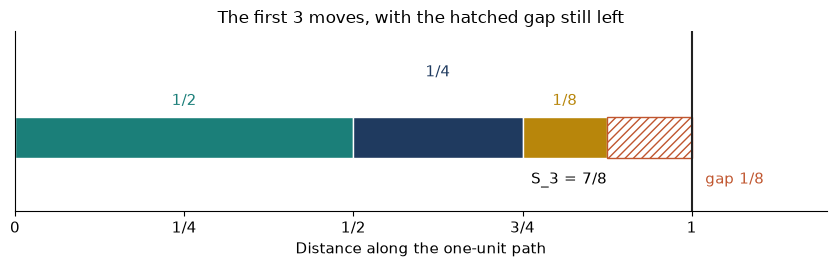

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 2.8))
cols = [TEAL, NAVY, GOLD, TERRA]
left = Fraction(0)
for k, t in enumerate(terms):
    ax.barh([0], [float(t)], left=[float(left)], height=0.5, color=cols[k % 4], edgecolor="white")
    ax.text(float(left + t / 2), 0.4 + 0.35 * (k % 2), frac(t), ha="center", color=cols[k % 4], fontsize=11)
    left += t
ax.barh([0], [float(gap)], left=[float(s)], height=0.5, color="white", edgecolor=TERRA, hatch="////")
ax.text(float(s), -0.42, f"S_{n} = {frac(s)}", ha="right", va="top")
ax.text(1.02, -0.42, f"gap {frac(gap)}", ha="left", va="top", color=TERRA)
ax.axvline(1.0, color=INK)
ax.set_xlim(0, 1.2); ax.set_ylim(-0.9, 1.3)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0]); ax.set_xticklabels(["0", "1/4", "1/2", "3/4", "1"])
ax.set_yticks([]); ax.grid(False)
ax.set_xlabel("Distance along the one-unit path")
show_fig("The first 3 moves, with the hatched gap still left")

**What this shows.** Each new piece is exactly half the remaining gap, so the gap halves and stays the same size as the last piece added. When a process keeps closing a fixed share of what remains, write the remaining gap as a formula instead of trusting a rounded display.

**Where it stops working.** This is an idealized sum on a one-unit path, not a claim about real distances or devices. Every $S_n$ is a finite sum; the value 1 belongs to the whole sequence, not to any one stage.

## 2. The multiplier decides

**Question in plain words:** The formula $a/(1-r)$ gives a number for almost any $r$. When does that number mean anything?

**Equations from the chapter:**

$$\frac{a}{1 - r} \qquad |r| < 1$$

**What the symbols mean:** $a$ is the first term and $r$ is the fixed multiplier from one term to the next. $|r|$ is the size of $r$ without its sign. The formula $a/(1-r)$ is the sum only when $|r| < 1$.

In [4]:
a = Fraction(1, 2)
RATIOS = [("1/2", Fraction(1, 2)), ("-1/2", Fraction(-1, 2)), ("1", Fraction(1)), ("2", Fraction(2))]

def partial_sums(r):
    out, total = [], Fraction(0)
    for k in range(8):
        total += a * r ** k
        out.append(total)
    return out

r = Fraction(1, 2)
sums = partial_sums(r)
print("Default: a = 1/2, r = 1/2. Each term is the one before times 1/2.")
print(f"  S_2 = 1/2 + {frac(a * r)} = {frac(sums[1])}")
print("  S_1 to S_4 = " + ", ".join(frac(x) for x in sums[:4]) + f";  S_8 = {frac(sums[-1])}")
print(f"  |r| = {frac(abs(r))} is below 1, so the formula applies:")
print(f"  a/(1 - r) = (1/2)/(1 - {frac(r)}) = (1/2)/({frac(1 - r)}) = {frac(a / (1 - r))}")
print()
print("All four multipliers from the reader's menu:")
for name, rr in RATIOS:
    ss = partial_sums(rr)
    first = ", ".join(frac(x) for x in ss[:4])
    if abs(rr) < 1:
        verdict = f"|r| < 1, so sum = (1/2)/(1 - ({frac(rr)})) = (1/2)/({frac(1 - rr)}) = {frac(a / (1 - rr))}"
    else:
        verdict = f"|r| < 1 FAILS. Plugging in anyway: (1/2)/(1 - {frac(rr)}) = " + ("division by 0" if rr == 1 else frac(a / (1 - rr)) + ", a negative number for a sum of positive terms")
    print(f"  r = {name}: S_1..S_4 = {first}; S_8 = {frac(ss[-1])}")
    print(f"      {verdict}")

Default: a = 1/2, r = 1/2. Each term is the one before times 1/2.
  S_2 = 1/2 + 1/4 = 3/4
  S_1 to S_4 = 1/2, 3/4, 7/8, 15/16;  S_8 = 255/256
  |r| = 1/2 is below 1, so the formula applies:
  a/(1 - r) = (1/2)/(1 - 1/2) = (1/2)/(1/2) = 1

All four multipliers from the reader's menu:
  r = 1/2: S_1..S_4 = 1/2, 3/4, 7/8, 15/16; S_8 = 255/256
      |r| < 1, so sum = (1/2)/(1 - (1/2)) = (1/2)/(1/2) = 1
  r = -1/2: S_1..S_4 = 1/2, 1/4, 3/8, 5/16; S_8 = 85/256
      |r| < 1, so sum = (1/2)/(1 - (-1/2)) = (1/2)/(3/2) = 1/3
  r = 1: S_1..S_4 = 1/2, 1, 3/2, 2; S_8 = 4
      |r| < 1 FAILS. Plugging in anyway: (1/2)/(1 - 1) = division by 0
  r = 2: S_1..S_4 = 1/2, 3/2, 7/2, 15/2; S_8 = 255/2
      |r| < 1 FAILS. Plugging in anyway: (1/2)/(1 - 2) = -1/2, a negative number for a sum of positive terms


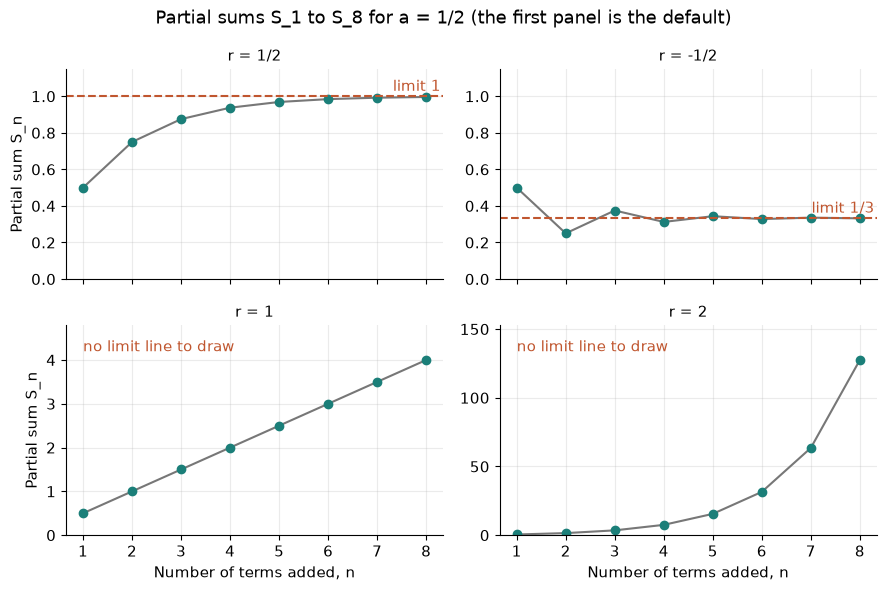

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
ns = np.arange(1, 9)
for ax, (name, rr) in zip(axes.ravel(), RATIOS):
    ss = [float(x) for x in partial_sums(rr)]
    ax.plot(ns, ss, "o-", color=GREY, markerfacecolor=TEAL, markeredgecolor=TEAL)
    if abs(rr) < 1:
        lim = float(a / (1 - rr))
        ax.axhline(lim, color=TERRA, linestyle="dashed")
        ax.text(8.3, lim + 0.03, f"limit {frac(a / (1 - rr))}", ha="right", color=TERRA)
        ax.set_ylim(0, 1.15)
    else:
        ax.text(1, max(ss) * 1.05, "no limit line to draw", color=TERRA)
        ax.set_ylim(0, max(ss) * 1.2)
    ax.set_title(f"r = {name}", fontsize=11)
    ax.set_xticks(ns)
for ax in axes[1]:
    ax.set_xlabel("Number of terms added, n")
for ax in axes[:, 0]:
    ax.set_ylabel("Partial sum S_n")
plt.suptitle("Partial sums S_1 to S_8 for a = 1/2 (the first panel is the default)")
show_fig()

**What this shows.** When $|r| < 1$ the terms shrink and the partial sums settle on $a/(1-r)$ (from below for $r = 1/2$, stepping above and below for $r = -1/2$). When it fails, the sums keep growing, and the formula's answer describes nothing about them. A fraction bar is not a permission slip: check the condition a shortcut was built on before using it.

**Where it stops working.** Here $a = 1/2$ throughout. Only eight partial sums are drawn; the limit claim rests on $|r| < 1$, not on the eight dots.

## 3. A tolerance you can meet and keep

**Question in plain words:** How many terms of a geometric series bring the gap from its limit $a/(1-r)$ below a requested size, and does it stay there?

**Equations from the chapter:**

$$S_n - rS_n = a - ar^n \qquad \text{gap after } n \text{ terms} = \frac{ar^n}{1 - r}$$

**What the symbols mean:** $S_n$ is the sum of the first $n$ terms, $a = 3$ is the first term, and $r$ is the multiplier. The gap from the limit after $n$ terms is $ar^n/(1-r)$. We use $a = 3$, $r = 1/4$ and ask for a gap below 0.01.

In [6]:
a, r, tol = Fraction(3), Fraction(1, 4), Fraction(1, 100)
limit = a / (1 - r)
print(f"Series: 3 + 3({frac(r)}) + 3({frac(r)})^2 + ...")
print(f"Limit: a/(1 - r) = 3/(1 - {frac(r)}) = 3/({frac(1 - r)}) = {frac(limit)}")
print()
print("Gap after n terms = 3(1/4)^n/(3/4):")
needed = None
for n in range(1, 8):
    g = a * r ** n / (1 - r)
    ok = g < tol
    print(f"  n = {n}: 3({frac(r ** n)})/({frac(1 - r)}) = {frac(g)}, about {dec(g)}   {'below 0.01' if ok else 'not below 0.01'}")
    if ok and needed is None:
        needed = n
print()
g = a * r ** needed / (1 - r)
gp = a * r ** (needed - 1) / (1 - r)
print(f"First n with gap below 0.01: n = {needed}")
print(f"At n = {needed}, the gap is 3 x {frac(r ** needed)} / ({frac(1 - r)}) = {frac(g)}, about {dec(g)}, which is below 0.01.")
print(f"At n = {needed - 1} it was {frac(gp)}, about {dec(gp)}, which is not.")
print(f"Each later step multiplies the gap by {frac(r)}, so every later gap stays below 0.01 too.")
print()
print("Other requests and multipliers from the reader's menu (first n that meets the request):")
for rr in [Fraction(1, 4), Fraction(1, 2)]:
    for tt in ["0.1", "0.01", "0.001"]:
        t = Fraction(tt)
        nn = next(n for n in range(1, 40) if a * rr ** n / (1 - rr) < t)
        print(f"  r = {frac(rr)}, request {tt}: n = {nn}")

Series: 3 + 3(1/4) + 3(1/4)^2 + ...
Limit: a/(1 - r) = 3/(1 - 1/4) = 3/(3/4) = 4

Gap after n terms = 3(1/4)^n/(3/4):
  n = 1: 3(1/4)/(3/4) = 1, about 1   not below 0.01
  n = 2: 3(1/16)/(3/4) = 1/4, about 0.25   not below 0.01
  n = 3: 3(1/64)/(3/4) = 1/16, about 0.0625   not below 0.01
  n = 4: 3(1/256)/(3/4) = 1/64, about 0.01563   not below 0.01
  n = 5: 3(1/1024)/(3/4) = 1/256, about 0.00391   below 0.01
  n = 6: 3(1/4096)/(3/4) = 1/1024, about 0.00098   below 0.01
  n = 7: 3(1/16384)/(3/4) = 1/4096, about 0.00024   below 0.01

First n with gap below 0.01: n = 5
At n = 5, the gap is 3 x 1/1024 / (3/4) = 1/256, about 0.00391, which is below 0.01.
At n = 4 it was 1/64, about 0.01563, which is not.
Each later step multiplies the gap by 1/4, so every later gap stays below 0.01 too.

Other requests and multipliers from the reader's menu (first n that meets the request):
  r = 1/4, request 0.1: n = 3
  r = 1/4, request 0.01: n = 5
  r = 1/4, request 0.001: n = 6
  r = 1/2, request 0.1: 

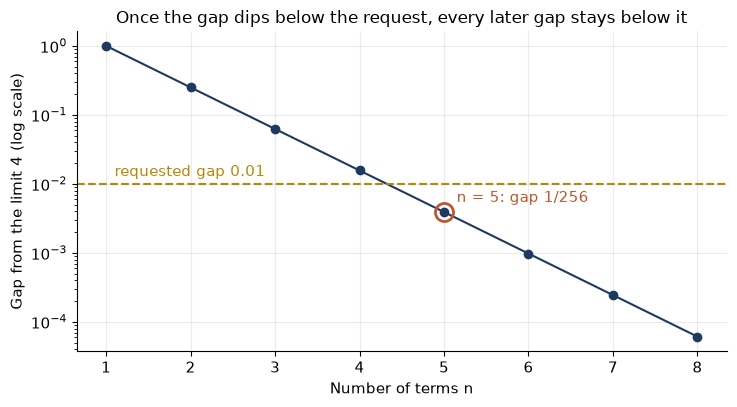

In [7]:
ns = np.arange(1, 9)
gaps = [float(a * r ** n / (1 - r)) for n in ns]
fig, ax = plt.subplots()
ax.semilogy(ns, gaps, "o-", color=NAVY)
ax.axhline(0.01, color=GOLD, linestyle="dashed")
ax.text(1.1, 0.013, "requested gap 0.01", color=GOLD)
ax.plot([needed], [gaps[needed - 1]], "o", markersize=13, markerfacecolor="none", markeredgecolor=TERRA, markeredgewidth=2)
ax.text(needed + 0.15, gaps[needed - 1] * 1.4, f"n = {needed}: gap {frac(g)}", color=TERRA)
ax.set_xlabel("Number of terms n")
ax.set_ylabel("Gap from the limit 4 (log scale)")
show_fig("Once the gap dips below the request, every later gap stays below it")

**What this shows.** The gap after $n$ terms is $ar^n/(1-r)$. It first dips below 0.01 at $n = 5$, and because each later gap is the previous one times $1/4$, it can never climb back above. That promise about every later stage is what convergence means. When a result must be accurate to a stated tolerance, solve for the stage that guarantees it, instead of stopping when one number looks close.

**Where it stops working.** The tail formula needs $|r| < 1$. A stricter request needs a later stage, and a sequence that is close once and then wanders off would not converge at all.

## 4. Continuity is a three-part check

**Question in plain words:** Given a hole, a jump, or a smooth line, which of the three conditions fails, and where?

**Equations from the chapter:**

$$f(x) = \frac{x^2 - 1}{x - 1} \qquad g(x) = x + 1$$

**What the symbols mean:** Continuity at $a$ needs three things: (1) $f(a)$ exists, (2) the limit as $x$ approaches $a$ exists, and (3) the two are equal. We test sample inputs a small step on each side of $a$. Here $a = 1$ and the step is 0.1.

In [8]:
a, h = Fraction(1), Fraction(1, 10)
left_x, right_x = a - h, a + h
print("f(x) = (x^2 - 1)/(x - 1). Factor the top: x^2 - 1 = (x - 1)(x + 1), so for x not equal to 1, f(x) = x + 1.")
print()
print(f"Left sample:  x = 1 - {dec(h)} = {dec(left_x)}:  f = {dec(left_x)} + 1 = {dec(left_x + 1)}")
print(f"Right sample: x = 1 + {dec(h)} = {dec(right_x)}:  f = {dec(right_x)} + 1 = {dec(right_x + 1)}")
print("Both sides head toward 2, so the limit exists and equals 2.")
print("But f(1) = (1 - 1)/(1 - 1) = 0/0, which has no value.")
print()
print("Condition 1 fails, so f is not continuous at 1. Defining f(1) = 2 would fill the hole.")
print()
print("The four functions from the reader's menu:")
rows = [("hole: f(x) = (x^2-1)/(x-1) at 1", "no value (0/0)", "2", "2", "condition 1 fails"),
        ("jump: 0 for x < 0, 2 for x >= 0, at 0", "2", "0", "2", "condition 2 fails (0 and 2 disagree)"),
        ("line: g(x) = x + 1 at 1", "2", "2", "2", "continuous"),
        ("moved: x + 1 but g(2) = 8, at 2", "8", "3", "3", "condition 3 fails (3 is not 8)")]
for name, val, l, r_, verdict in rows:
    print(f"  {name}: value {val}, left -> {l}, right -> {r_}: {verdict}")

f(x) = (x^2 - 1)/(x - 1). Factor the top: x^2 - 1 = (x - 1)(x + 1), so for x not equal to 1, f(x) = x + 1.

Left sample:  x = 1 - 0.1 = 0.9:  f = 0.9 + 1 = 1.9
Right sample: x = 1 + 0.1 = 1.1:  f = 1.1 + 1 = 2.1
Both sides head toward 2, so the limit exists and equals 2.
But f(1) = (1 - 1)/(1 - 1) = 0/0, which has no value.

Condition 1 fails, so f is not continuous at 1. Defining f(1) = 2 would fill the hole.

The four functions from the reader's menu:
  hole: f(x) = (x^2-1)/(x-1) at 1: value no value (0/0), left -> 2, right -> 2: condition 1 fails
  jump: 0 for x < 0, 2 for x >= 0, at 0: value 2, left -> 0, right -> 2: condition 2 fails (0 and 2 disagree)
  line: g(x) = x + 1 at 1: value 2, left -> 2, right -> 2: continuous
  moved: x + 1 but g(2) = 8, at 2: value 8, left -> 3, right -> 3: condition 3 fails (3 is not 8)


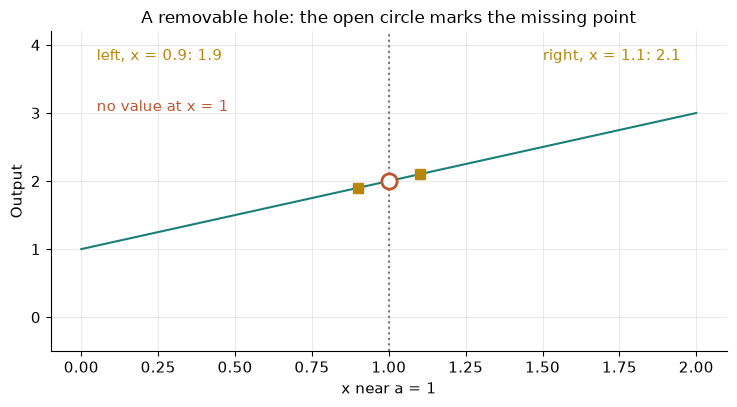

In [9]:
fig, ax = plt.subplots()
xs = np.linspace(0, 2, 81)
ax.plot(xs, xs + 1, color=TEAL)
ax.plot([1], [2], "o", markersize=11, markerfacecolor="white", markeredgecolor=TERRA, markeredgewidth=2, zorder=5)
ax.plot([0.9, 1.1], [1.9, 2.1], "s", color=GOLD, markersize=7)
ax.text(0.05, 3.95, "left, x = 0.9: 1.9", color=GOLD, va="top")
ax.text(1.95, 3.95, "right, x = 1.1: 2.1", color=GOLD, va="top", ha="right")
ax.text(0.05, 3.2, "no value at x = 1", color=TERRA, va="top")
ax.axvline(1, color=GREY, linestyle=":")
ax.set_ylim(-0.5, 4.2)
ax.set_xlabel("x near a = 1")
ax.set_ylabel("Output")
show_fig("A removable hole: the open circle marks the missing point")

**What this shows.** The curve shows the nearby behavior; the dot at $a$ shows the assigned value, or an open circle where there is none. Continuity asks the two to agree. When a graph looks connected, run the three checks anyway: a drawing can hide a single missing or misplaced point.

**Where it stops working.** Samples are evidence, not proof. The factoring $x^2 - 1 = (x-1)(x+1)$ is what covers every input near 1, and the jump's two sides are fixed by its definition.

## Practice

**1.** What is $S_5$ for the half-distance path, and what gap does it leave?

<details><summary>Show answer</summary>

$S_5 = 1 - \frac{1}{2^5} = 1 - \frac{1}{32} = \frac{31}{32}$, leaving a gap of $\frac{1}{32}$.

</details>

**2.** With $a = \frac12$ and $r = -\frac12$, what are $S_1$, $S_2$, $S_3$, and what is $a/(1-r)$?

<details><summary>Show answer</summary>

$S_1 = \frac12$. $S_2 = \frac12 - \frac14 = \frac14$. $S_3 = \frac14 + \frac18 = \frac38$. And $\frac{1/2}{1 - (-1/2)} = \frac{1/2}{3/2} = \frac13$.

</details>

**3.** With $a = 3$ and $r = \frac14$, what is the sum after 3 terms, and how much is left?

<details><summary>Show answer</summary>

$3 + \frac34 + \frac{3}{16} = \frac{48}{16} + \frac{12}{16} + \frac{3}{16} = \frac{63}{16}$. The limit is 4, so what is left is $4 - \frac{63}{16} = \frac{64}{16} - \frac{63}{16} = \frac{1}{16}$.

</details>

**4.** For $f(x) = (x^2 - 1)/(x - 1)$, what is $f(0.99)$, and which value would make $f$ continuous at 1?

<details><summary>Show answer</summary>

$f(0.99) = 0.99 + 1 = 1.99$. Both sides approach 2, so defining $f(1) = 2$ fills the hole.

</details>